
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# Semicontinuity and the Extreme Value Theorem

**Prerequisites:** [Continuous Functions](function-continuity.ipynb) · [Supremum and Infimum](supremum-infimum.ipynb) · [Nested Interval Property](nested-interval-property.ipynb)

$f : S \to \mathbb{R}$ has a **maximum** at $c \in S$ if $f(x) \le f(c)$ for all $x \in S$, and a **minimum** if $f(x) \ge f(c)$ for all $x \in S$. A maximum need not exist even for bounded $f$: $f(x) = x$ on $(0, 1)$ has supremum $1$ but no maximum, and on $[0,1]$ the function $f(x) = x$ ($x < 1$), $f(1) = 0$ has none either. The first fails because the domain is not closed, the second because $f$ jumps **down** at $1$. Only one half of continuity is needed to exclude the second failure.

::: {#def-semicontinuity}
## Semicontinuity

$f$ is **upper semicontinuous** (usc) at $a \in S$ if
$$\forall \varepsilon > 0\ \exists \delta > 0\ \forall x \in S,\ |x - a| < \delta: \quad f(x) < f(a) + \varepsilon,$$
and **lower semicontinuous** (lsc) at $a$ if instead $f(x) > f(a) - \varepsilon$. So $f$ is continuous at $a$ if and only if it is both usc and lsc at $a$, and $f$ is lsc if and only if $-f$ is usc.
:::

::: {#thm-usc-max}
## Semicontinuous Functions on $[a, b]$ Attain Extrema

If $f : [a, b] \to \mathbb{R}$ is upper semicontinuous, it is bounded above and has a maximum. If $f$ is lower semicontinuous, it is bounded below and has a minimum.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-usc-max
Let $f$ be usc; the lsc case follows by applying this to $-f$. Both steps bisect $[a, b]$ and use the [nested interval property](nested-interval-property.ipynb): the chosen halves $I_0 \supseteq I_1 \supseteq \dots$ have lengths $(b - a)2^{-n}$ and shrink to a point $c$; for every $\delta > 0$, $I_n \subseteq (c - \delta, c + \delta)$ for $n$ large.

*Bounded above.* If $f$ is unbounded above on an interval, it is unbounded above on one of its halves; choose that half each time. usc at $c$ with $\varepsilon = 1$ gives $f < f(c) + 1$ on $(c - \delta, c + \delta) \cap [a, b]$, which contains some $I_n$ on which $f$ is unbounded: contradiction.

*Maximum attained.* Let $M = \sup f$ and suppose $f(x) < M$ for all $x$. The supremum over an interval is the larger of the suprema over its halves, so we can choose halves with $\sup_{I_n} f = M$ for all $n$. At the limit point $c$, $f(c) < M$; usc with $\varepsilon = \frac{M - f(c)}{2}$ gives $f < \frac{M + f(c)}{2}$ on a neighbourhood containing some $I_n$, so $\sup_{I_n} f \le \frac{M + f(c)}{2} < M$: contradiction. $\blacksquare$
:::

::: {#cor-evt}
## Extreme Value Theorem

A continuous $f : [a, b] \to \mathbb{R}$ is bounded and attains a maximum and a minimum.
:::

The same statement for continuous functions on compact metric spaces is proved in [Continuity and Compactness](continuity-and-compactness.ipynb).

::: {#exm-semicontinuous}
## One Extremum Without the Other

1. $f(x) = x - \lfloor x \rfloor$ on $[0, 1]$, i.e. $f(x) = x$ for $x < 1$ and $f(1) = 0$, is lsc but not usc at $1$. It has the minimum $0$ but no maximum ($\sup f = 1$).
2. $g(x) = \lfloor x \rfloor - x$ on $[0, 1]$, i.e. $g(x) = -x$ for $x < 1$ and $g(1) = 0$, is usc but not lsc at $1$. It has the maximum $0$ (at $0$ and at $1$) but no minimum ($\inf g = -1$).
:::

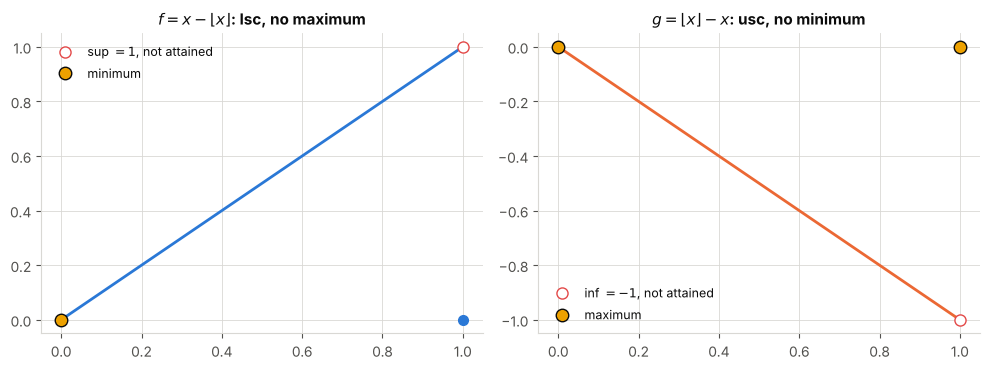

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

x = np.linspace(0, 1, 200, endpoint=False)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
ax.plot(x, x, color=BLUE, lw=2)
ax.plot(1, 1, "o", mfc="white", mec=RED, ms=8, label="sup $= 1$, not attained")
ax.plot(1, 0, "o", color=BLUE, ms=7)
ax.plot(0, 0, "o", color=YELLOW, mec=INK, ms=9, label="minimum")
ax.set_title(r"$f = x - \lfloor x \rfloor$: lsc, no maximum"); ax.legend(loc="upper left", fontsize=9)
ax2.plot(x, -x, color=ORANGE, lw=2)
ax2.plot(1, -1, "o", mfc="white", mec=RED, ms=8, label="inf $= -1$, not attained")
ax2.plot([0, 1], [0, 0], "o", color=YELLOW, mec=INK, ms=9, label="maximum")
ax2.set_title(r"$g = \lfloor x \rfloor - x$: usc, no minimum"); ax2.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()